In [16]:
import json
import pandas as pd


In [17]:
with open('/Users/benny/AI-Engineer/data/meta_Books.jsonl', 'r') as f:
    first_5_line = [json.loads(f.readline()) for _ in range(5)]

In [18]:
first_5_line

[{'main_category': 'Books',
  'title': 'Chaucer',
  'subtitle': 'Hardcover – Import, January 1, 2004',
  'author': {'avatar': 'https://m.media-amazon.com/images/I/21Je2zja9pL._SY600_.jpg',
   'name': 'Peter Ackroyd',
   'about': ['Peter Ackroyd, (born 5 October 1949) is an English biographer, novelist and critic with a particular interest in the history and culture of London. For his novels about English history and culture and his biographies of, among others, William Blake, Charles Dickens, T. S. Eliot and Sir Thomas More, he won the Somerset Maugham Award and two Whitbread Awards. He is noted for the volume of work he has produced, the range of styles therein, his skill at assuming different voices and the depth of his research.',
    'He was elected a fellow of the Royal Society of Literature in 1984 and appointed a Commander of the Order of the British Empire in 2003.',
    'Bio from Wikipedia, the free encyclopedia.']},
  'average_rating': 4.5,
  'rating_number': 29,
  'features'

In [19]:
def filter_category(data:dict)-> bool:
    """
    Filter the category of the data.
    """
    filter = False
    if len(data['categories']) > 1 and 'Fiction' in data['categories'][1]:
        filter = True
    return filter

In [20]:
with open('/Users/benny/AI-Engineer/data/meta_Books.jsonl', 'r') as fp:
    with open('/Users/benny/AI-Engineer/data/meta_Books_fiction.jsonl', 'w') as fw:
        i = 0
        for line in fp:
            data = json.loads(line)
            if filter_category(data):
                fw.write(json.dumps(data) + '\n')
            i +=1
            if i % 100000 == 0:
                print(f'Processed {i} lines')


Processed 100000 lines
Processed 200000 lines
Processed 300000 lines
Processed 400000 lines
Processed 500000 lines
Processed 600000 lines
Processed 700000 lines
Processed 800000 lines
Processed 900000 lines
Processed 1000000 lines
Processed 1100000 lines
Processed 1200000 lines
Processed 1300000 lines
Processed 1400000 lines
Processed 1500000 lines
Processed 1600000 lines
Processed 1700000 lines
Processed 1800000 lines
Processed 1900000 lines
Processed 2000000 lines
Processed 2100000 lines
Processed 2200000 lines
Processed 2300000 lines
Processed 2400000 lines
Processed 2500000 lines
Processed 2600000 lines
Processed 2700000 lines
Processed 2800000 lines
Processed 2900000 lines
Processed 3000000 lines
Processed 3100000 lines
Processed 3200000 lines
Processed 3300000 lines
Processed 3400000 lines
Processed 3500000 lines
Processed 3600000 lines
Processed 3700000 lines
Processed 3800000 lines
Processed 3900000 lines
Processed 4000000 lines
Processed 4100000 lines
Processed 4200000 lines
P

In [21]:
with open('/Users/benny/AI-Engineer/data/meta_Books_fiction.jsonl', 'r') as f:
    first_5_fiction_line = [json.loads(f.readline()) for _ in range(5)]

first_5_fiction_line

[{'main_category': 'Books',
  'title': 'Chaucer',
  'subtitle': 'Hardcover – Import, January 1, 2004',
  'author': {'avatar': 'https://m.media-amazon.com/images/I/21Je2zja9pL._SY600_.jpg',
   'name': 'Peter Ackroyd',
   'about': ['Peter Ackroyd, (born 5 October 1949) is an English biographer, novelist and critic with a particular interest in the history and culture of London. For his novels about English history and culture and his biographies of, among others, William Blake, Charles Dickens, T. S. Eliot and Sir Thomas More, he won the Somerset Maugham Award and two Whitbread Awards. He is noted for the volume of work he has produced, the range of styles therein, his skill at assuming different voices and the depth of his research.',
    'He was elected a fellow of the Royal Society of Literature in 1984 and appointed a Commander of the Order of the British Empire in 2003.',
    'Bio from Wikipedia, the free encyclopedia.']},
  'average_rating': 4.5,
  'rating_number': 29,
  'features'

In [22]:
with open('/Users/benny/AI-Engineer/data/meta_Books_fiction.jsonl', 'r') as f:
    data= [json.loads(line) for line in f]

sum_rating_number = 0

for i in range(len(data)):
    if data[i]['rating_number'] is not None:
        sum_rating_number += int(data[i]['rating_number'])

average_rating_number = sum_rating_number / len(data)

In [23]:
average_rating_number

922.5454144405301

In [24]:
from statistics import median

ratings = [
    int(item["rating_number"])
    for item in data
    if item["rating_number"] is not None
]

print(median(ratings))

print(sum(item["rating_number"] is None for item in data))

23
0


We see that the number is extremely skew, so it is reasonable to use medium which is more robust than mean.

In [29]:
def filter_rating_number(data:dict)-> bool:
    """
    Filter the rating_number of the data.
    """
    filter = False
    if int(data['rating_number']) > 23:
        filter = True
    return filter

In [30]:
with open('/Users/benny/AI-Engineer/data/meta_Books_fiction.jsonl', 'r') as fp:
    with open('/Users/benny/AI-Engineer/data/meta_Books_fiction_rating_filtered.jsonl', 'w') as fw:
        i = 0
        for line in fp:
            data = json.loads(line)
            if filter_rating_number(data):
                fw.write(json.dumps(data) + '\n')
            i +=1
            if i % 100000 == 0:
                print(f'Processed {i} lines')

Processed 100000 lines
Processed 200000 lines
Processed 300000 lines
Processed 400000 lines
Processed 500000 lines
Processed 600000 lines
Processed 700000 lines


### There are still quite a lot of data I want to see ways I can compress it or a more specific sections that I am interested in

In [31]:
df = pd.read_json('/Users/benny/AI-Engineer/data/meta_Books_fiction_rating_filtered.jsonl', lines=True)

In [33]:
len(df)

396836

In [34]:
print(df.head(5))

  main_category                                              title  \
0         Books                                            Chaucer   
1         Books  Heart of Silk and Shadows: A Fae Fantasy Roman...   
2         Books                                 Girl Made of Glass   
3         Books             Sugary Sweets (A Taste of Love Series)   
4         Books                                    Therapy Mammals   

                              subtitle  \
0  Hardcover – Import, January 1, 2004   
1             Paperback – May 29, 2022   
2         Paperback – January 24, 2023   
3          Paperback – August 18, 2016   
4            Paperback – June 12, 2018   

                                              author  average_rating  \
0  {'avatar': 'https://m.media-amazon.com/images/...             4.5   
1  {'avatar': 'https://m.media-amazon.com/images/...             4.4   
2  {'avatar': 'https://m.media-amazon.com/images/...             4.5   
3  {'avatar': 'https://m.media-amazon.

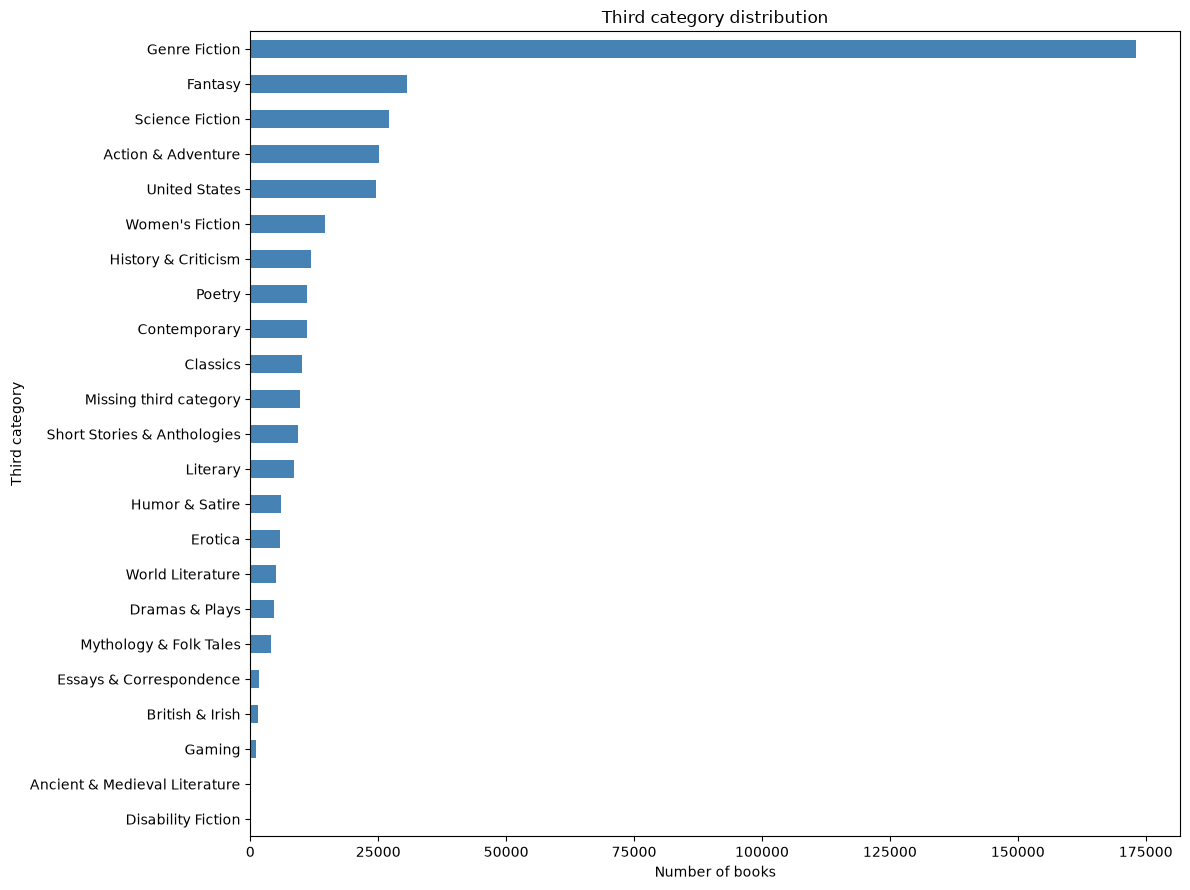

In [38]:
import matplotlib.pyplot as plt

third_category = df["categories"].str[2].fillna("Missing third category")
category_counts = third_category.value_counts()

category_counts.sort_values().plot.barh(
    figsize=(12, 9),
    color="steelblue",
)

plt.title("Third category distribution")
plt.xlabel("Number of books")
plt.ylabel("Third category")
plt.tight_layout()
plt.show()

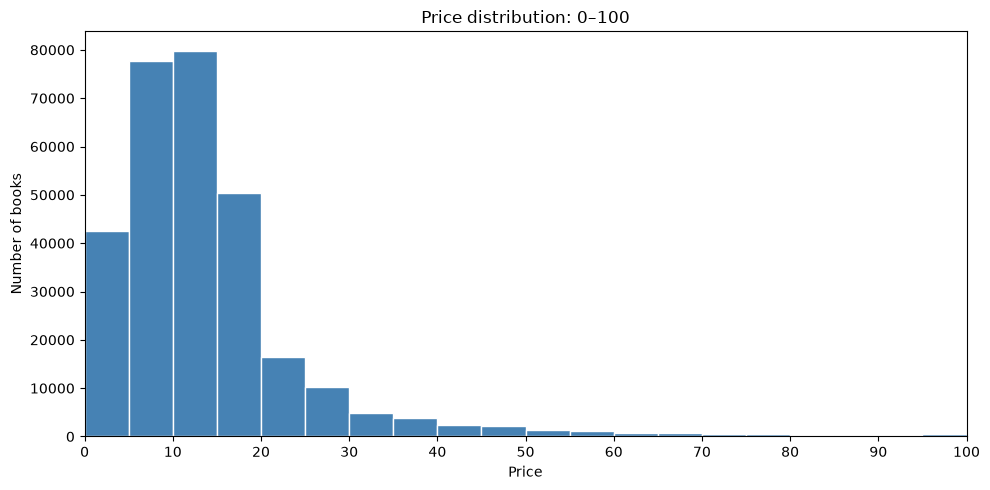

In [44]:
prices = pd.to_numeric(df["price"], errors="coerce").dropna()


prices.plot.hist(
    bins=range(0, 105, 5),
    figsize=(10, 5),
    color="steelblue",
    edgecolor="white",
)

plt.xlim(0, 100)
plt.xticks(range(0, 101, 10))
plt.title("Price distribution: 0–100")
plt.xlabel("Price")
plt.ylabel("Number of books")
plt.tight_layout()
plt.show()

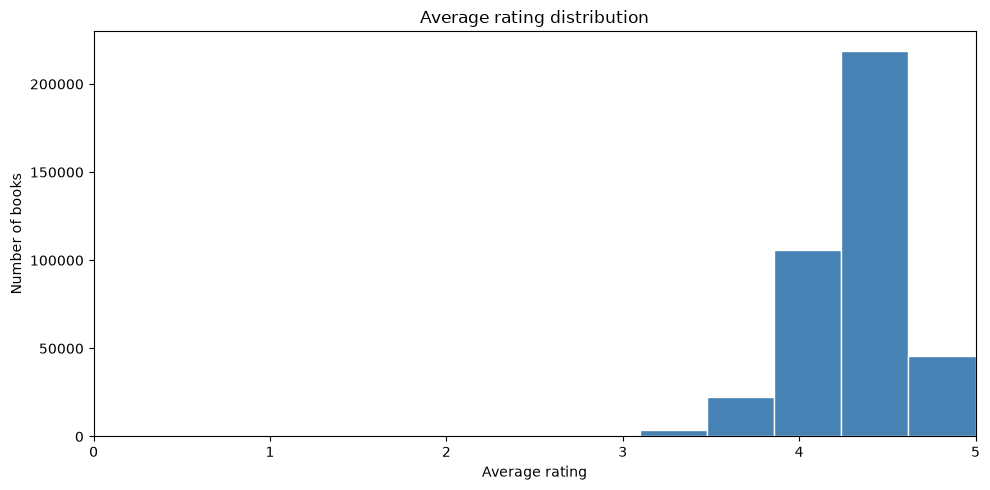

In [48]:
average_ratings = pd.to_numeric(df["average_rating"], errors="coerce").dropna()


average_ratings.plot.hist(
    figsize=(10, 5),
    color="steelblue",
    edgecolor="white",
)

plt.xlim(0, 5)
plt.title("Average rating distribution")
plt.xlabel("Average rating")
plt.ylabel("Number of books")
plt.tight_layout()
plt.show()

In [49]:
df_1000 = df.sample(n=1000, random_state=42)

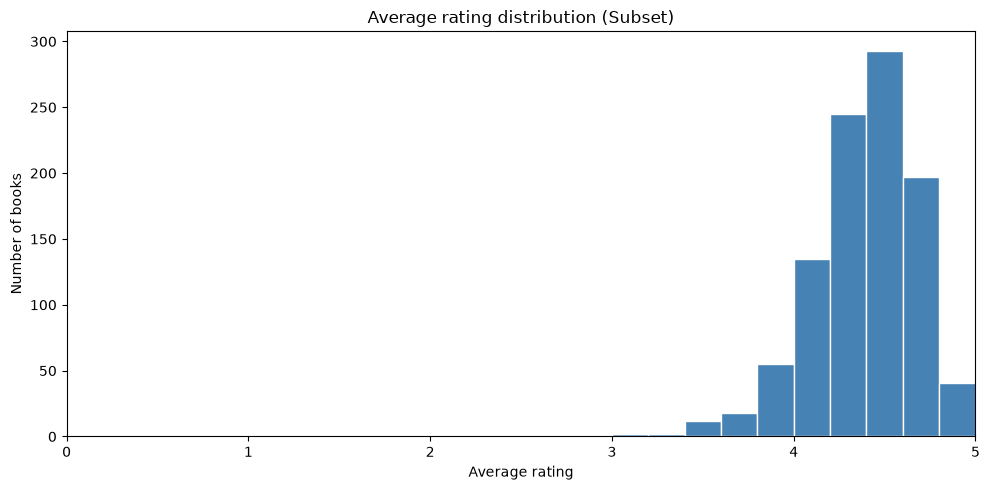

In [50]:
average_ratings_subset = pd.to_numeric(df_1000["average_rating"], errors="coerce").dropna()


average_ratings_subset.plot.hist(
    figsize=(10, 5),
    color="steelblue",
    edgecolor="white",
)

plt.xlim(0, 5)
plt.title("Average rating distribution (Subset)")
plt.xlabel("Average rating")
plt.ylabel("Number of books")
plt.tight_layout()
plt.show()

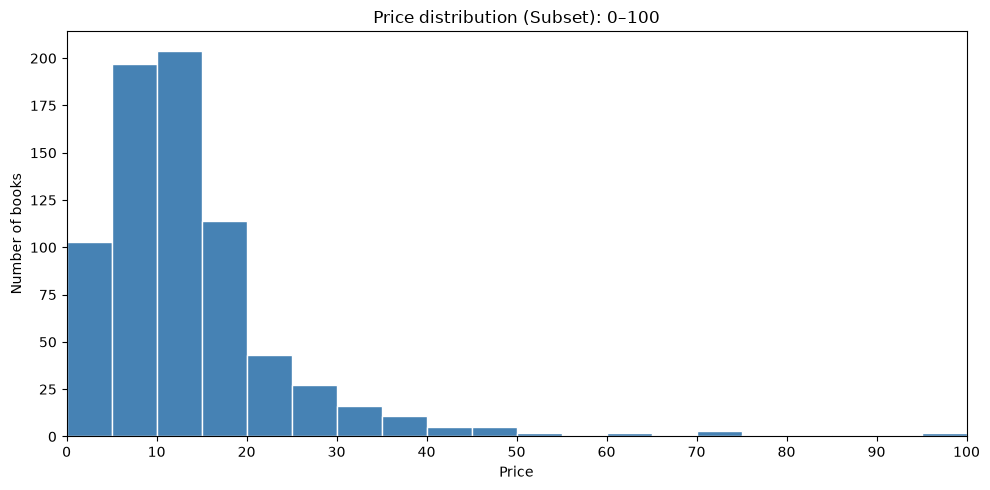

In [51]:
prices_subset = pd.to_numeric(df_1000["price"], errors="coerce").dropna()


prices_subset.plot.hist(
    bins=range(0, 105, 5),
    figsize=(10, 5),
    color="steelblue",
    edgecolor="white",
)

plt.xlim(0, 100)
plt.xticks(range(0, 101, 10))
plt.title("Price distribution (Subset): 0–100")
plt.xlabel("Price")
plt.ylabel("Number of books")
plt.tight_layout()
plt.show()

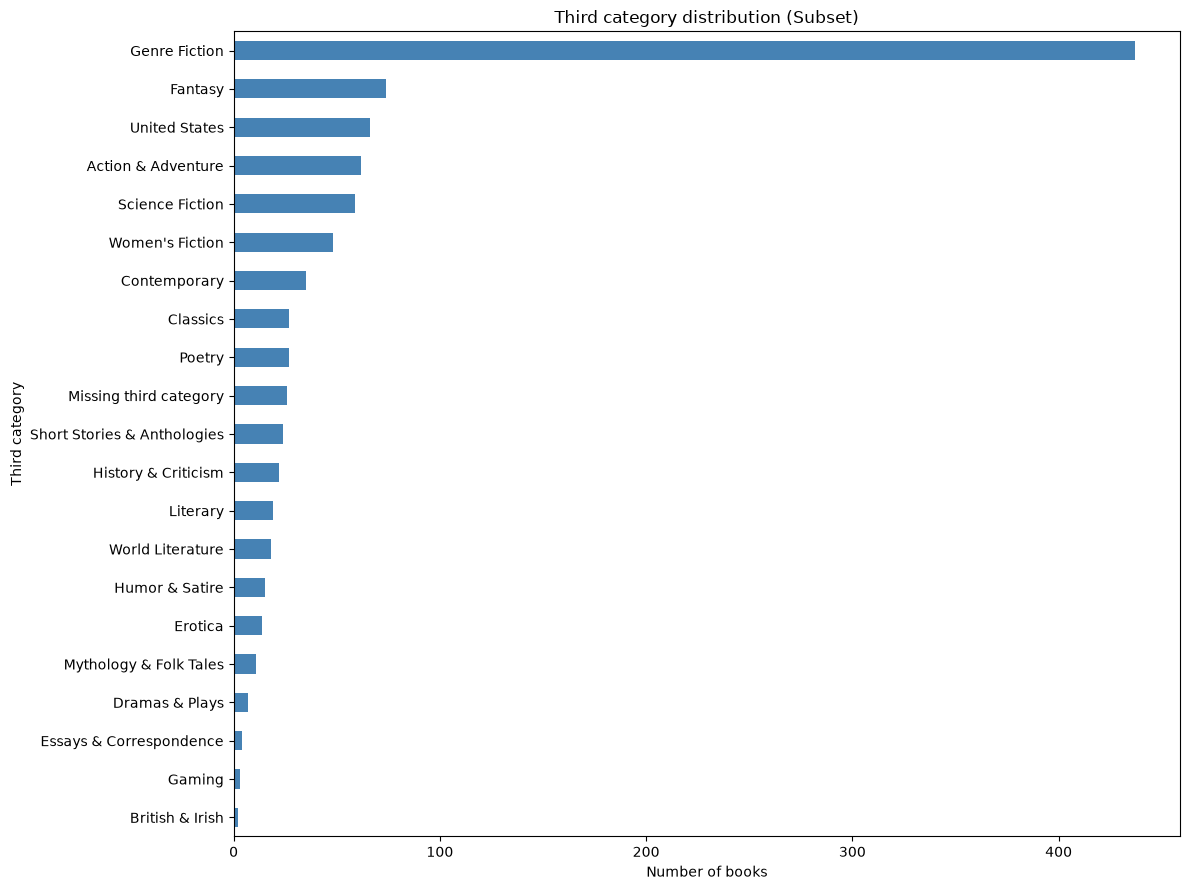

In [52]:
third_category_subset = df_1000["categories"].str[2].fillna("Missing third category")
category_counts = third_category_subset.value_counts()

category_counts.sort_values().plot.barh(
    figsize=(12, 9),
    color="steelblue",
)

plt.title("Third category distribution (Subset)")
plt.xlabel("Number of books")
plt.ylabel("Third category")
plt.tight_layout()
plt.show()

In [53]:
df_1000.to_json('/Users/benny/AI-Engineer/data/meta_Books_fiction_rating_filtered_subset.jsonl', orient='records', lines=True)

### Combine meta and review tables and export as jsonl and save them in the data folder

In [55]:
sample_ids = set(df_1000["parent_asin"].dropna())
matching_chunks = []

for chunk in pd.read_json(
    "/Users/benny/AI-Engineer/data/Books.jsonl",
    lines=True,
    chunksize=50_000,
):
    matches = chunk[chunk["parent_asin"].isin(sample_ids)]
    matching_chunks.append(matches)

sample_reviews = pd.concat(matching_chunks, ignore_index=True)

# Add the sampled books' metadata to each review.
joined_df = sample_reviews.merge(
    df_1000,
    on="parent_asin",
    how="inner",
    suffixes=("_review", "_book"),
    validate="many_to_one",
)

print(f"Reviews: {len(joined_df):,}")
print(f"Books with reviews: {joined_df['parent_asin'].nunique():,}")

Reviews: 12,945
Books with reviews: 999


In [56]:
joined_df.to_json(
    "/Users/benny/AI-Engineer/data/reviews_from_sampled_data.jsonl",
    orient="records",
    lines=True,
)

/var/folders/5z/wcks6d7s4437774b8bx3385w0000gn/T/ipykernel_38424/4043995486.py:1: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  joined_df.to_json(
